# Fine-tuning de SciBERT para clasificar la función de cita

Este notebook ajusta `allenai/scibert_scivocab_uncased` para predecir `selected_function` a partir de:

- **Contexto:** `left_context + citing_sentence + right_context`.
- **Chunks:** `chunk_text1 + chunk_section1`, `chunk_text2 + chunk_section2` y `chunk_text3 + chunk_section3`.

Los datos se leen de tres archivos generados previamente con datos balanceados: `train.json`, `val.json` y `test.json`.

**Formato de entrada del modelo** (cada pieza se trunca por separado para que ninguna quede fuera):

```
[CLS] contexto [SEP] chunk 1 [SEP] chunk 2 [SEP] chunk 3 [SEP]
```


## 1. Conexión con los directorios

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 2. Dependencias y GPU


In [2]:
!pip -q install -U transformers accelerate scikit-learn --quiet

In [ ]:
import torch
print("PyTorch:", torch.__version__)
print("GPU disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Sin GPU.")

PyTorch: 2.14.1+cu130
GPU disponible: True
GPU: Tesla T4


## 3. Parámetros


In [22]:
import os, json, random, inspect, time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DRIVE_DIR = "/content/drive/MyDrive/Colab Notebooks/proyecto"
DATA_DIR = f"{DRIVE_DIR}/data"
TRAIN_PATH = f"{DATA_DIR}/train.json"
VAL_PATH = f"{DATA_DIR}/val.json"
TEST_PATH = f"{DATA_DIR}/test.json"
OUTPUT_DIR = f"{DRIVE_DIR}/models/scibert"

LABEL_COL = "selected_function"
ORIGIN_COL = "origin" # manual / doc_manual / real / synthetic
SECTION_FIRST = True

MODEL_NAME = "allenai/scibert_scivocab_uncased"
MAX_LEN = 512
MAX_CONTEXT_TOKENS = 200

EPOCHS = 3
BATCH_SIZE = 16
GRAD_ACCUM = 2
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_STEPS = 350
PATIENCE = 2
SEED = 42

try:
    os.makedirs(OUTPUT_DIR, exist_ok=True)
except OSError:
    print("Aviso: no se pudo crear OUTPUT_DIR (¿Drive sin montar?).")
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

## 4. Carga de los tres archivos de datos

In [5]:
REQUIRED = ["left_context", "citing_sentence", "right_context", LABEL_COL] + [f"chunk_{p}{k}" for k in (1, 2, 3) for p in ("text", "section")]

def load_split(path):
    if not os.path.exists(path):
        raise FileNotFoundError(f"No existe {path}.")
    with open(path, encoding="utf-8") as f:
        recs = json.load(f)
    faltan = [c for c in REQUIRED if any(c not in r for r in recs[:1000])]
    if faltan:
        raise KeyError(f"Faltan campos en {os.path.basename(path)}: {faltan}")
    return recs

train_recs = load_split(TRAIN_PATH)
val_recs = load_split(VAL_PATH)
test_recs = load_split(TEST_PATH)

print(f"train: {len(train_recs)} | val: {len(val_recs)} | test: {len(test_recs)}")

dist = pd.DataFrame({
    "train": Counter(r[LABEL_COL] for r in train_recs),
    "val": Counter(r[LABEL_COL] for r in val_recs),
    "test": Counter(r[LABEL_COL] for r in test_recs),
}).fillna(0).astype(int)
dist.loc["TOTAL"] = dist.sum()
display(dist)

if ORIGIN_COL in train_recs[0]:
    orig = pd.DataFrame({
        "train": Counter(r.get(ORIGIN_COL) for r in train_recs),
        "val": Counter(r.get(ORIGIN_COL) for r in val_recs),
        "test": Counter(r.get(ORIGIN_COL) for r in test_recs),
    }).fillna(0).astype(int)
    print("Origen de los datos por grupo:")
    display(orig)

train: 28224 | val: 6048 | test: 6048


,train,val,test
Identification of the Originator,3136,672,672
Evidence,3136,672,672
Gap,3136,672,672
Further Reading,3136,672,672
Basis,3136,672,672
Improvement/Modification,3136,672,672
Background,3136,672,672
Comparison,3136,672,672
Application,3136,672,672
TOTAL,28224,6048,6048


Origen de los datos por grupo:


,train,val,test
real,7842,1682,0
synthetic,20382,4366,2329
doc_manual,0,0,3249
manual,0,0,470


## 5. Construcción de las entradas

- **Contexto:** `left_context + citing_sentence + right_context`, unidos con espacios.
- **Chunk *k*:** La sección (`chunk_section{k}`) y el texto (`chunk_text{k}`). Por defecto la sección va primero (`"Introduction: ..."`), así el truncado nunca la elimina.

In [6]:
def _s(x):
    return x.strip() if isinstance(x, str) else ""

def build_context(r):
    partes = (_s(r.get("left_context")), _s(r.get("citing_sentence")), _s(r.get("right_context")))
    return " ".join(p for p in partes if p)

def build_chunk(r, k):
    sec, txt = _s(r.get(f"chunk_section{k}")), _s(r.get(f"chunk_text{k}"))
    if sec and txt:
        return f"{sec}: {txt}" if SECTION_FIRST else f"{txt} ({sec})"
    return txt or sec

ej = train_recs[0]
print("Etiqueta :", ej[LABEL_COL])
print("\nCONTEXTO :", build_context(ej)[:600])
for k in (1, 2, 3):
    print(f"\nCHUNK {k}  :", build_chunk(ej, k)[:300])

vacios = pd.DataFrame({
    f"chunk {k}": [sum(1 for r in recs if not build_chunk(r, k)) for recs in (train_recs, val_recs, test_recs)]
    for k in (1, 2, 3)}, index=["train", "val", "test"])
print("\nChunks vacíos por grupo:")
display(vacios)

Etiqueta : Identification of the Originator

CONTEXTO : With my own verification tool (Isabelle), I would continue to push first-order logic and set theory as a basis for verification until the late 90s, when the dominance of higher-order logic became overwhelming. Until that date, many theorem provers did not even support negative numbers; it was suddenly urgent to deal with floating-point arithmetic and numerical algorithms. Harrison tackled this ; he went on to accomplish great things in formalised mathematics, including verifying a floating-point exponential function and (much later) playing a major role in verifying the celebrated Kepler conje

CHUNK 1  : Text formalization: Because the original proof was not used for the formalization, we cannot assert that the original proof has been formally verified to be error free. Similarly, we cannot assert that the computer code for the original proof is free of bugs. The detection and correction of small er

CHUNK 2  : Importing results 

,chunk 1,chunk 2,chunk 3
train,0,49,107
val,0,0,9
test,0,8,12


### Etiquetas

In [7]:
LABELS = sorted({r[LABEL_COL] for r in train_recs})
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}

extra = {r[LABEL_COL] for r in val_recs + test_recs} - set(LABELS)
assert not extra, f"Etiquetas en val/test que no están en train: {extra}"
assert all(r[LABEL_COL] for r in train_recs + val_recs + test_recs), "Hay citas sin selected_function"

print(f"{len(LABELS)} clases:")
for l, i in label2id.items():
    print(f"  {i}: {l}")

9 clases:
  0: Application
  1: Background
  2: Basis
  3: Comparison
  4: Evidence
  5: Further Reading
  6: Gap
  7: Identification of the Originator
  8: Improvement/Modification


## 6. Tokenización con SciBERT

Cada pieza (contexto y los tres chunks) se tokeniza sin tokens especiales, se trunca según su presupuesto y se arma la secuencia `[CLS] contexto [SEP] chunk 1 [SEP] chunk 2 [SEP] chunk 3 [SEP]`.

In [8]:
from transformers import AutoTokenizer, set_seed

set_seed(SEED)
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
tok.model_max_length = 1_000_000
CLS, SEP = tok.cls_token_id, tok.sep_token_id
print("Tokenizador:", MODEL_NAME, "| vocabulario:", tok.vocab_size)

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/228k [00:00<?, ?B/s]

Tokenizador: allenai/scibert_scivocab_uncased | vocabulario: 31090


Tokenización lista en 78s


,train,val,test
longitud mediana,367.0,378.0,429.0
longitud p90,512.0,512.0,512.0
longitud máx.,512.0,512.0,512.0
% contexto truncado,8.2,14.6,14.6
% con algún chunk truncado,15.7,16.0,35.5
% de tokens de chunks conservados,89.0,88.5,79.8


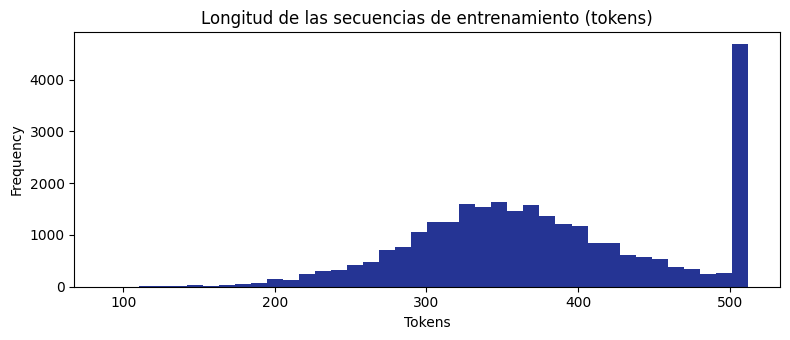

Ejemplo decodificado:
 [CLS] with my own verification tool ( isabelle ), i would continue to push first - order logic and set theory as a basis for verification until the late 90s, when the dominance of higher - order logic became overwhelming. until that date, many theorem provers did not even support negative numbers ; it was suddenly urgent to deal with floating - point arithmetic and numerical algorithms. harrison tackled this ; he went on to accomplish great things in formalised mathematics, including verifying a floating - point exponential function and ( much later ) playing a major role in verifying the celebrated kepler conjecture # citation _ tag. another landmark was the verification of probabilistic al ...


In [9]:
def allocate(lengths, budget):
    alloc = [0] * len(lengths)
    remaining = budget
    order = sorted(range(len(lengths)), key=lambda i: lengths[i])
    for pos, i in enumerate(order):
        share = remaining // (len(order) - pos)
        alloc[i] = min(lengths[i], share)
        remaining -= alloc[i]
    return alloc

def encode_records(recs, tokenizer, batch=2000):
    ctx, chs = [], [[], [], []]
    for s in range(0, len(recs), batch):
        part = recs[s:s + batch]
        ctx += tokenizer([build_context(r) for r in part], add_special_tokens=False)["input_ids"]
        for k in (1, 2, 3):
            chs[k - 1] += tokenizer([build_chunk(r, k) for r in part], add_special_tokens=False)["input_ids"]

    enc, info = [], []
    for i in range(len(recs)):
        c = ctx[i][:MAX_CONTEXT_TOKENS]
        pieces = [chs[0][i], chs[1][i], chs[2][i]]
        budget = max(0, MAX_LEN - len(c) - 5)            # 5 = [CLS] + 4 [SEP]
        alloc = allocate([len(p) for p in pieces], budget)

        ids = [CLS] + c + [SEP]
        types = [0] * len(ids)
        for p, a in zip(pieces, alloc):
            seg = p[:a] + [SEP]
            ids += seg
            types += [1] * len(seg)
        assert len(ids) <= MAX_LEN
        enc.append({"input_ids": ids, "token_type_ids": types, "attention_mask": [1] * len(ids)})
        info.append({"longitud": len(ids), "contexto_original": len(ctx[i]),
                     "contexto_truncado": len(ctx[i]) > MAX_CONTEXT_TOKENS,
                     "chunks_originales": sum(len(p) for p in pieces),
                     "chunks_conservados": sum(alloc),
                     "chunks_truncados": any(len(p) > a for p, a in zip(pieces, alloc))})
    return enc, pd.DataFrame(info)

t0 = time.time()
train_enc, train_info = encode_records(train_recs, tok)
val_enc, val_info = encode_records(val_recs, tok)
test_enc, test_info = encode_records(test_recs, tok)
print(f"Tokenización lista en {time.time() - t0:.0f}s")

resumen = pd.DataFrame({
    n: {"longitud mediana": info["longitud"].median(),
        "longitud p90": info["longitud"].quantile(0.9),
        "longitud máx.": info["longitud"].max(),
        "% contexto truncado": info["contexto_truncado"].mean() * 100,
        "% con algún chunk truncado": info["chunks_truncados"].mean() * 100,
        "% de tokens de chunks conservados": info["chunks_conservados"].sum() / max(1, info["chunks_originales"].sum()) * 100}
    for n, info in (("train", train_info), ("val", val_info), ("test", test_info))}).round(1)
display(resumen)

fig, ax = plt.subplots(figsize=(8, 3.5))
train_info["longitud"].plot.hist(bins=40, ax=ax, color="#253494")
ax.set_title("Longitud de las secuencias de entrenamiento (tokens)"); ax.set_xlabel("Tokens")
plt.tight_layout(); plt.show()

dec = tok.decode(train_enc[0]["input_ids"])
print("Ejemplo decodificado:\n", dec[:700], "...")

## 7. Dataset, modelo y métricas

In [10]:
from torch.utils.data import Dataset
from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding

class CitationDataset(Dataset):
    def __init__(self, enc, labels):
        self.enc, self.labels = enc, labels
    def __len__(self):
        return len(self.enc)
    def __getitem__(self, i):
        item = dict(self.enc[i])
        item["labels"] = self.labels[i]
        return item

y_train = [label2id[r[LABEL_COL]] for r in train_recs]
y_val = [label2id[r[LABEL_COL]] for r in val_recs]
y_test = [label2id[r[LABEL_COL]] for r in test_recs]

train_ds = CitationDataset(train_enc, y_train)
val_ds = CitationDataset(val_enc, y_val)
test_ds = CitationDataset(test_enc, y_test)
collator = DataCollatorWithPadding(tokenizer=tok, pad_to_multiple_of=8)

model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=len(LABELS), id2label=id2label, label2id=label2id)
print(f"Parámetros del modelo: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  442MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  442MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those

Parámetros del modelo: 109.9 M


In [11]:
from sklearn.metrics import accuracy_score, f1_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds),
            "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
            "weighted_f1": f1_score(labels, preds, average="weighted", zero_division=0)}

## 8. Entrenamiento

Los grupos están balanceados por clase, así que se usa pérdida estándar sin pesos. Se evalúa al final de cada época y se conserva el modelo con mejor **macro-F1 en validación**; el entrenamiento se detiene si no mejora durante `PATIENCE` épocas.

In [25]:
import inspect, math, os, torch
from transformers import TrainingArguments, Trainer, EarlyStoppingCallback

ta_params = inspect.signature(TrainingArguments.__init__).parameters
eval_key = "eval_strategy" if "eval_strategy" in ta_params else "evaluation_strategy"

use_bf16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()

extra_args = {}
if "group_by_length" in ta_params:
    extra_args["group_by_length"] = True

args = TrainingArguments(
    output_dir=os.path.join(OUTPUT_DIR, "checkpoints"),
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    warmup_steps=WARMUP_STEPS,
    **{eval_key: "epoch"},
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    logging_steps=50,
    bf16=use_bf16,
    fp16=torch.cuda.is_available() and not use_bf16,
    dataloader_num_workers=2,
    report_to="none",
    seed=SEED,
    **extra_args,
)

tr_params = inspect.signature(Trainer.__init__).parameters
tok_kw = {"processing_class": tok} if "processing_class" in tr_params else {"tokenizer": tok}

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)],
    **tok_kw,
)

pasos_por_epoca = math.ceil(len(train_ds) / (BATCH_SIZE * GRAD_ACCUM))
pasos = pasos_por_epoca * EPOCHS
print(f"Lote efectivo: {BATCH_SIZE * GRAD_ACCUM} | pasos/época: {pasos_por_epoca} | pasos totales aprox.: {pasos}")

Lote efectivo: 32 | pasos/época: 882 | pasos totales aprox.: 2646


In [26]:
t0 = time.time()
train_result = trainer.train()
print(f"Entrenamiento terminado en {(time.time() - t0) / 60:.1f} min")
print("Mejor checkpoint:", trainer.state.best_model_checkpoint)

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,2.045004,1.493609,0.512070,0.514310,0.514310
2,1.052607,1.721068,0.509590,0.514098,0.514098
3,0.535247,1.997585,0.500661,0.505395,0.505395


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Entrenamiento terminado en 208.3 min
Mejor checkpoint: /content/drive/MyDrive/Colab Notebooks/proyecto/models/scibert/checkpoints/checkpoint-882


### Curvas de entrenamiento

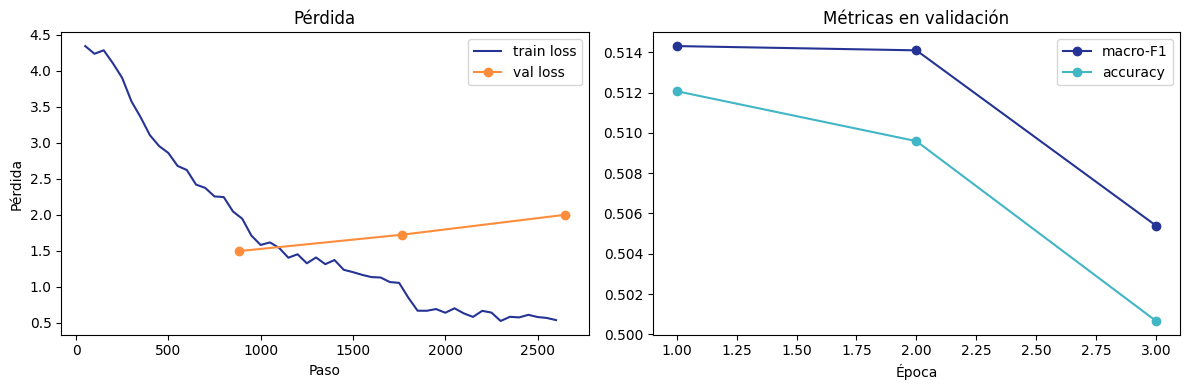

,epoch,eval_loss,eval_accuracy,eval_macro_f1,eval_weighted_f1
17,1.0,1.4936,0.5121,0.5143,0.5143
36,2.0,1.7211,0.5096,0.5141,0.5141
54,3.0,1.9976,0.5007,0.5054,0.5054


In [27]:
hist = pd.DataFrame(trainer.state.log_history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
tr = hist.dropna(subset=["loss"])
axes[0].plot(tr["step"], tr["loss"], label="train loss", color="#253494")
ev = hist.dropna(subset=["eval_loss"])
axes[0].plot(ev["step"], ev["eval_loss"], "o-", label="val loss", color="#fd8d3c")
axes[0].set_xlabel("Paso"); axes[0].set_ylabel("Pérdida"); axes[0].set_title("Pérdida"); axes[0].legend()

axes[1].plot(ev["epoch"], ev["eval_macro_f1"], "o-", label="macro-F1", color="#253494")
axes[1].plot(ev["epoch"], ev["eval_accuracy"], "o-", label="accuracy", color="#41b6c4")
axes[1].set_xlabel("Época"); axes[1].set_title("Métricas en validación"); axes[1].legend()
plt.tight_layout(); plt.show()

display(ev[["epoch", "eval_loss", "eval_accuracy", "eval_macro_f1", "eval_weighted_f1"]].round(4))

## 9. Evaluación

Se evalúan validación y pruebas completas, y además por **origen del dato**, porque una parte de ambos grupos es sintética. Las métricas de `real` y `manual` son las más confiables.

In [28]:
from sklearn.metrics import classification_report, confusion_matrix

def predict(ds):
    out = trainer.predict(ds)
    logits = out.predictions[0] if isinstance(out.predictions, tuple) else out.predictions
    e = np.exp(logits - logits.max(axis=1, keepdims=True))
    probs = e / e.sum(axis=1, keepdims=True)
    return probs.argmax(axis=1), probs

val_pred, val_probs = predict(val_ds)
test_pred, test_probs = predict(test_ds)
y_val_a, y_test_a = np.array(y_val), np.array(y_test)

def global_metrics(y, p):
    present = sorted(set(y))
    return {"n": len(y), "accuracy": accuracy_score(y, p),
            "macro_f1": f1_score(y, p, labels=present, average="macro", zero_division=0)}

rows = {"val (completo)": global_metrics(y_val_a, val_pred), "test (completo)": global_metrics(y_test_a, test_pred)}
for name, recs, y, p in (("val", val_recs, y_val_a, val_pred), ("test", test_recs, y_test_a, test_pred)):
    origins = np.array([r.get(ORIGIN_COL, "desconocido") for r in recs])
    rows[f"{name} (solo reales, sin sintéticos)"] = global_metrics(y[origins != "synthetic"], p[origins != "synthetic"]) if (origins != "synthetic").any() else None
    for o in ("manual", "doc_manual", "real", "synthetic"):
        m = origins == o
        if m.any():
            rows[f"{name} · origin={o}"] = global_metrics(y[m], p[m])
resumen_eval = pd.DataFrame({k: v for k, v in rows.items() if v}).T
resumen_eval["n"] = resumen_eval["n"].astype(int)
display(resumen_eval.round(4))
print("macro_f1 se calcula sobre las clases presentes en cada subconjunto (las manuales no cubren todas las clases).")

,n,accuracy,macro_f1
val (completo),6048,0.5121,0.5143
test (completo),6048,0.4291,0.4213
"val (solo reales, sin sintéticos)",1682,0.5357,0.5153
val · origin=real,1682,0.5357,0.5153
val · origin=synthetic,4366,0.5030,0.4947
"test (solo reales, sin sintéticos)",3719,0.4152,0.4060
test · origin=manual,470,0.4872,0.5680
test · origin=doc_manual,3249,0.4047,0.3879
test · origin=synthetic,2329,0.4513,0.4504


macro_f1 se calcula sobre las clases presentes en cada subconjunto (las manuales no cubren todas las clases).


In [29]:
rep = classification_report(y_test_a, test_pred, labels=list(range(len(LABELS))),
                            target_names=LABELS, output_dict=True, zero_division=0)
print("Reporte por clase en pruebas (completo):")
display(pd.DataFrame(rep).T.round(3))

origins_test = np.array([r.get(ORIGIN_COL, "desconocido") for r in test_recs])
mask = origins_test != "synthetic"
rep_real = classification_report(y_test_a[mask], test_pred[mask], labels=list(range(len(LABELS))),
                                 target_names=LABELS, output_dict=True, zero_division=0)
print("Reporte por clase en pruebas (solo datos reales):")
display(pd.DataFrame(rep_real).T.round(3))

Reporte por clase en pruebas (completo):


,precision,recall,f1-score,support
Application,0.365,0.610,0.457,672.000
Background,0.459,0.513,0.485,672.000
Basis,0.409,0.490,0.446,672.000
Comparison,0.292,0.546,0.381,672.000
Evidence,0.552,0.484,0.515,672.000
Further Reading,0.411,0.168,0.239,672.000
Gap,0.590,0.487,0.533,672.000
Identification of the Originator,0.523,0.222,0.311,672.000
Improvement/Modification,0.561,0.342,0.425,672.000
accuracy,0.429,0.429,0.429,0.429


Reporte por clase en pruebas (solo datos reales):


,precision,recall,f1-score,support
Application,0.252,0.644,0.362,267.000
Background,0.492,0.530,0.510,517.000
Basis,0.434,0.507,0.468,440.000
Comparison,0.259,0.585,0.359,357.000
Evidence,0.639,0.476,0.545,532.000
Further Reading,0.628,0.168,0.265,672.000
Gap,0.531,0.456,0.491,353.000
Identification of the Originator,0.473,0.188,0.269,330.000
Improvement/Modification,0.513,0.307,0.384,251.000
accuracy,0.415,0.415,0.415,0.415


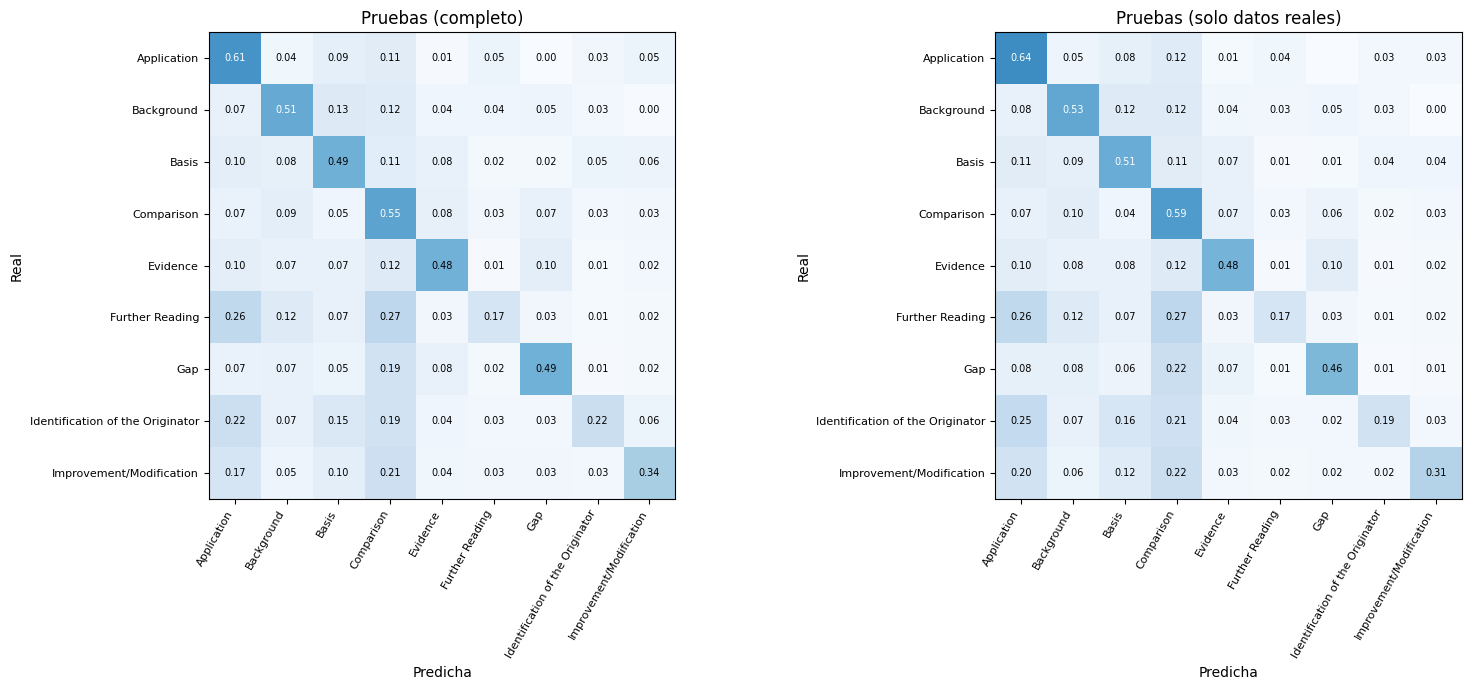

In [30]:
def plot_cm(y, p, title, ax):
    cm = confusion_matrix(y, p, labels=list(range(len(LABELS))))
    cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(LABELS))); ax.set_yticks(range(len(LABELS)))
    ax.set_xticklabels(LABELS, rotation=60, ha="right", fontsize=8); ax.set_yticklabels(LABELS, fontsize=8)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            if cm[i, j]:
                ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_title(title); ax.set_xlabel("Predicha"); ax.set_ylabel("Real")
    return im

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
plot_cm(y_test_a, test_pred, "Pruebas (completo)", axes[0])
plot_cm(y_test_a[mask], test_pred[mask], "Pruebas (solo datos reales)", axes[1])
plt.tight_layout(); plt.show()

## 10. Guardar modelo, métricas y predicciones

In [31]:
final_dir = os.path.join(OUTPUT_DIR, "final")
trainer.save_model(final_dir)
tok.save_pretrained(final_dir)

with open(os.path.join(final_dir, "labels.json"), "w", encoding="utf-8") as f:
    json.dump({"label2id": label2id, "id2label": {str(k): v for k, v in id2label.items()}}, f, ensure_ascii=False, indent=2)

resumen_eval.round(4).to_csv(os.path.join(OUTPUT_DIR, "metricas_evaluacion.csv"))

pred_df = pd.DataFrame({
    "record_key": [r.get("record_key") for r in test_recs],
    "citing_arxiv_id": [r.get("citing_arxiv_id") for r in test_recs],
    "origin": [r.get(ORIGIN_COL) for r in test_recs],
    "real": [id2label[i] for i in y_test_a],
    "predicha": [id2label[i] for i in test_pred],
    "confianza": test_probs.max(axis=1).round(4),
})
pred_df.to_csv(os.path.join(OUTPUT_DIR, "predicciones_test.csv"), index=False)
print("Guardado en", OUTPUT_DIR)
display(pred_df.head())

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Guardado en /content/drive/MyDrive/Colab Notebooks/proyecto/models/scibert


,record_key,citing_arxiv_id,origin,real,predicha,confianza
0,2bc9ee824e3f8705,1908.02651,doc_manual,Evidence,Basis,0.3650
1,a62324181cb27d61,1908.02651,doc_manual,Identification of the Originator,Background,0.2820
2,43eab8545bdc571d,1908.02651,doc_manual,Further Reading,Basis,0.5800
3,3e766de160fef493,1908.02651,doc_manual,Evidence,Evidence,0.3930
4,08510fce64fcdd3d,1908.02651,doc_manual,Evidence,Evidence,0.8548


## 11. Inferencia con el modelo ajustado

In [32]:
@torch.no_grad()
def predict_citations(records, top_k=3):
    enc, _ = encode_records(records, tok)
    model.eval()
    dev = next(model.parameters()).device
    resultados = []
    for e in enc:
        batch = {k: torch.tensor([v], device=dev) for k, v in e.items()}
        probs = torch.softmax(model(**batch).logits, dim=-1)[0].cpu().numpy()
        top = probs.argsort()[::-1][:top_k]
        resultados.append([(id2label[int(i)], round(float(probs[i]), 3)) for i in top])
    return resultados

muestra = test_recs[:3]
for r, pred in zip(muestra, predict_citations(muestra)):
    print("Oración   :", r["citing_sentence"][:200])
    print("Real      :", r[LABEL_COL])
    print("Predicción:", pred, "\n")

Oración   : The laws of parallel computing result in the actual behavior of the computing systems the more difference from that expected on the basis of the classical computing the more communication takes place 
Real      : Evidence
Predicción: [('Basis', 0.365), ('Evidence', 0.327), ('Background', 0.189)] 

Oración   : The mentioned decrease of the system's performance manifests in the appearance of the performance wall , #CITATION_TAG, a new limitation due to the parallelized sequential computing.
Real      : Identification of the Originator
Predicción: [('Background', 0.282), ('Evidence', 0.245), ('Gap', 0.147)] 

Oración   : The limits of single-processor performance enforced by the laws of nature are topped by the limitations of parallel computing , #CITATION_TAG, and further limited through introducing the "biological c
Real      : Further Reading
Predicción: [('Basis', 0.58), ('Background', 0.236), ('Identification of the Originator', 0.078)] 

